In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os

carpeta_salida = "TAREA9"
os.makedirs(carpeta_salida, exist_ok=True)

In [2]:
#### CONSTANTES FÍSICAS
## Se trabaja en años.
## Caso principal: 238U, por ser el isótopo mayoritario del uranio natural.

T12_U238 = 4.47e9       # semivida del 238U, años
T12_U235 = 7.04e8       # semivida del 235U, años

Lambda = np.log(2) / T12_U238
Lambda_U235 = np.log(2) / T12_U235

NA = 6.02214076e23      # constante de Avogadro, mol^-1
M_U = 238.02891         # masa molar aproximada del uranio natural, g/mol
abundancia_U238 = 0.992742
abundancia_U235 = 0.007204

# Masa de referencia.
# Se usa 1 mg para mantener N0 dentro del rango entero manejable por np.random.binomial.
masa_ref_U = 1.0e-3     # g de uranio natural

N_U_ref = int((masa_ref_U / M_U) * NA)
n0 = int(N_U_ref * abundancia_U238)      # núcleos iniciales de 238U
n0_U235_ref = int(N_U_ref * abundancia_U235)

np.random.seed(123)

print(f"lambda_238 = {Lambda:.4e} años^-1")
print(f"lambda_235 = {Lambda_U235:.4e} años^-1")
print(f"N0(238U) para {masa_ref_U:g} g de uranio natural = {n0:.4e}")
print(f"N0(235U) para {masa_ref_U:g} g de uranio natural = {n0_U235_ref:.4e}")

lambda_238 = 1.5507e-10 años^-1
lambda_235 = 9.8458e-10 años^-1
N0(238U) para 0.001 g de uranio natural = 2.5116e+18
N0(235U) para 0.001 g de uranio natural = 1.8226e+16


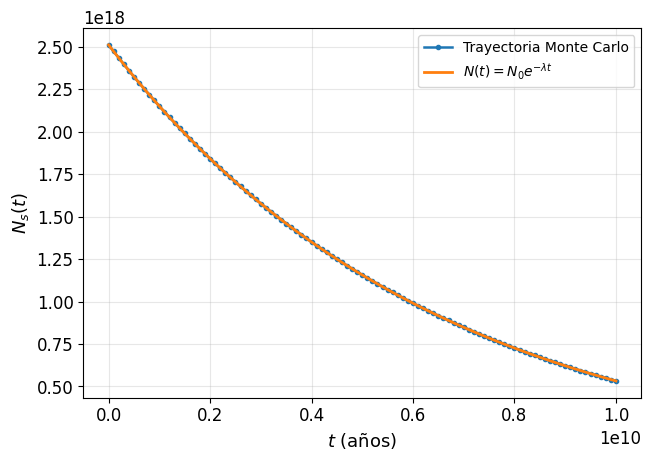

In [3]:
#########################################################
########## EVOLUCIÓN TEMPORAL DE UNA TRAYECTORIA ########
#########################################################

# Se escoge un tiempo total del orden de unas pocas semividas del 238U.
t_real = 1.0e10      # años
dt1 = 1.0e8          # años
u1 = int(t_real / dt1)

# Vectores
t_1 = np.arange(u1 + 1) * dt1
Np1 = np.zeros(u1 + 1)

# Condición inicial
N1 = n0
Np1[0] = N1

# Probabilidad de supervivencia en cada intervalo dt
q_step = np.exp(-Lambda * dt1)

# Simulación Monte Carlo: una trayectoria
for j in range(1, u1 + 1):
    N1 = np.random.binomial(int(N1), q_step)
    Np1[j] = N1

# Curva teórica
Np_teorico_1 = n0 * np.exp(-Lambda * t_1)


#########################################################
########## GRÁFICA DE UNA TRAYECTORIA ###################
#########################################################

plt.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 10,
    "figure.figsize": (7.2, 4.8),
    "axes.grid": False,
    "lines.linewidth": 1.8
})

plt.plot(t_1, Np1, 'o-', markersize=3, label='Trayectoria Monte Carlo')
plt.plot(t_1, Np_teorico_1, '-', linewidth=2, label=r"$N(t)=N_0e^{-\lambda t}$")

plt.xlabel('$t$ (años)')
plt.ylabel('$N_s(t)$')
plt.legend()
plt.grid(True, alpha=0.3)

plt.savefig(os.path.join(carpeta_salida, 'U_E1_trayectoria_U238.png'), dpi=300, bbox_inches='tight')
plt.show()

,t_real (años),t_est medio (años),s_t muestral (años),sigma_t analítica (años),error relativo muestral (%),error relativo analítico (%)
0,1.000e+08,1.000e+08,0.521,0.509,5.210e-07,5.087e-07
1,5.000e+08,5.000e+08,1.078,1.155,2.157e-07,2.311e-07
2,1.000e+09,1.000e+09,1.690,1.667,1.690e-07,1.667e-07
3,2.000e+09,2.000e+09,2.448,2.454,1.224e-07,1.227e-07
4,3.000e+09,3.000e+09,3.090,3.132,1.030e-07,1.044e-07
5,4.470e+09,4.470e+09,4.048,4.069,9.056e-08,9.103e-08
6,6.000e+09,6.000e+09,5.155,5.042,8.591e-08,8.404e-08
7,8.000e+09,8.000e+09,6.139,6.379,7.673e-08,7.974e-08


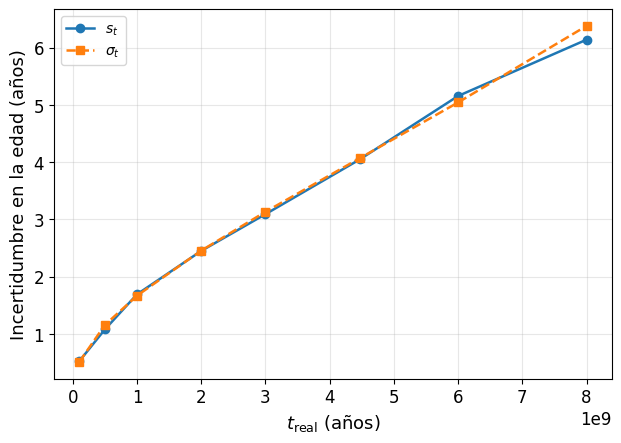

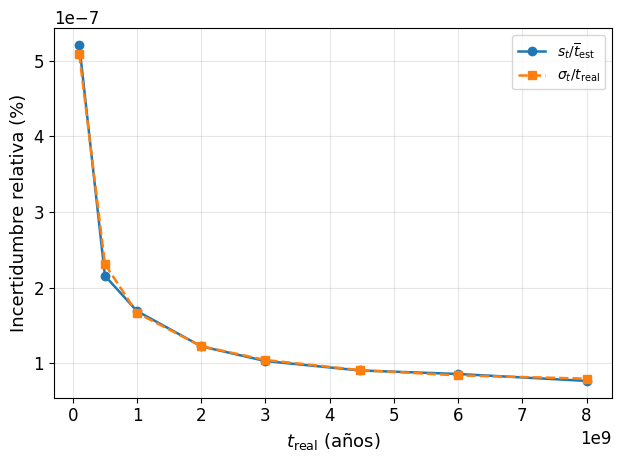

In [4]:
#########################################################
########## ESTIMACIÓN DE EDAD PARA DISTINTOS t_real #####
#########################################################

# Tiempos reales representativos para escalas geológicas.
tiempos_reales = np.array([
    1.0e8, 5.0e8, 1.0e9, 2.0e9,
    3.0e9, 4.47e9, 6.0e9, 8.0e9
])

# Número de simulaciones independientes
M = 500

# Arrays para guardar resultados
media_t_est = np.zeros(len(tiempos_reales))
s_t_muestral = np.zeros(len(tiempos_reales))
sigma_t_analitica = np.zeros(len(tiempos_reales))
error_relativo_muestral = np.zeros(len(tiempos_reales))
error_relativo_analitico = np.zeros(len(tiempos_reales))

for i, t_real in enumerate(tiempos_reales):

    # Probabilidad de supervivencia hasta t_real
    q = np.exp(-Lambda * t_real)

    # M simulaciones independientes del número de núcleos supervivientes
    Np_final = np.random.binomial(n0, q, size=M)

    # Evitar logaritmos de cero, por si en algún caso la muestra queda agotada
    Np_final = Np_final[Np_final > 0]

    # Estimación de la edad en cada simulación
    t_est = -(1 / Lambda) * np.log(Np_final / n0)

    # Media muestral de la edad estimada
    media_t_est[i] = np.mean(t_est)

    # Desviación típica muestral de la edad estimada
    s_t_muestral[i] = np.std(t_est, ddof=1)

    # Incertidumbre analítica
    sigma_t_analitica[i] = (1 / Lambda) * np.sqrt(
        (np.exp(Lambda * t_real) - 1) / n0
    )

    # Incertidumbre relativa muestral
    error_relativo_muestral[i] = s_t_muestral[i] / media_t_est[i]

    # Incertidumbre relativa analítica
    error_relativo_analitico[i] = sigma_t_analitica[i] / t_real


#########################################################
########## MOSTRAR TABLA ################################
#########################################################

tabla_E2 = pd.DataFrame({
    't_real (años)': tiempos_reales,
    't_est medio (años)': media_t_est,
    's_t muestral (años)': s_t_muestral,
    'sigma_t analítica (años)': sigma_t_analitica,
    'error relativo muestral (%)': 100 * error_relativo_muestral,
    'error relativo analítico (%)': 100 * error_relativo_analitico
})

display(
    tabla_E2.style.format({
        't_real (años)': '{:.3e}',
        't_est medio (años)': '{:.3e}',
        's_t muestral (años)': '{:.3f}',
        'sigma_t analítica (años)': '{:.3f}',
        'error relativo muestral (%)': '{:.3e}',
        'error relativo analítico (%)': '{:.3e}'
    })
)


#########################################################
########## TABLA LÁTEX ##################################
#########################################################

def formato_coma(x, decimales):
    return f"{x:.{decimales}f}".replace(".", ",")

tabla_E2_latex = pd.DataFrame({
    r'$t_{\mathrm{real}}$ ($10^8$ años)': tiempos_reales / 1e8,
    r'$\overline{t}_{\mathrm{est}}$ ($10^8$ años)': media_t_est / 1e8,
    r'$s_t$ (años)': s_t_muestral,
    r'$\sigma_t$ (años)': sigma_t_analitica,

    # Se reescalan las incertidumbres relativas porque son muy pequeñas.
    r'$s_t/\overline{t}_{\mathrm{est}}$ ($10^{-6}\%$)': 1e6 * 100 * error_relativo_muestral,
    r'$\sigma_t/t_{\mathrm{real}}$ ($10^{-6}\%$)': 1e6 * 100 * error_relativo_analitico
})

codigo_latex_E2 = tabla_E2_latex.to_latex(
    index=False,
    escape=False,
    formatters={
        r'$t_{\mathrm{real}}$ ($10^8$ años)': lambda x: formato_coma(x, 2),
        r'$\overline{t}_{\mathrm{est}}$ ($10^8$ años)': lambda x: formato_coma(x, 2),
        r'$s_t$ (años)': lambda x: formato_coma(x, 3),
        r'$\sigma_t$ (años)': lambda x: formato_coma(x, 3),
        r'$s_t/\overline{t}_{\mathrm{est}}$ ($10^{-6}\%$)': lambda x: formato_coma(x, 3),
        r'$\sigma_t/t_{\mathrm{real}}$ ($10^{-6}\%$)': lambda x: formato_coma(x, 3)
    }
)

with open(os.path.join(carpeta_salida, 'U_tabla_E2_estimacion_edad.tex'), 'w', encoding='utf-8') as f:
    f.write(codigo_latex_E2)


#########################################################
##### GRÁFICA INCERTIDUMBRES MUESTRAL Y ANALÍTICA ######
#########################################################

plt.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 10,
    "figure.figsize": (7.2, 4.8),
    "axes.grid": False,
    "lines.linewidth": 1.8
})

plt.plot(tiempos_reales, s_t_muestral, 'o-', label=r'$s_t$')
plt.plot(tiempos_reales, sigma_t_analitica, 's--', label=r'$\sigma_t$')

plt.xlabel(r'$t_{\mathrm{real}}$ (años)')
plt.ylabel(r'Incertidumbre en la edad (años)')
plt.ticklabel_format(style='sci', axis='x', scilimits=(0, 0))

plt.legend()
plt.grid(True, alpha=0.3)

plt.savefig(os.path.join(carpeta_salida, 'U_E2_comparacion_incertidumbre.png'), dpi=300, bbox_inches='tight')
plt.show()


#########################################################
# GRÁFICA INCERTIDUMBRES RELATIVA MUESTRAL Y ANALÍTICA #
#########################################################

plt.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 10,
    "figure.figsize": (7.2, 4.8),
    "axes.grid": False,
    "lines.linewidth": 1.8
})

plt.plot(tiempos_reales, 100 * error_relativo_muestral, 'o-', label=r'$s_t/\overline{t}_{\mathrm{est}}$')
plt.plot(tiempos_reales, 100 * error_relativo_analitico, 's--', label=r'$\sigma_t/t_{\mathrm{real}}$')

plt.xlabel(r'$t_{\mathrm{real}}$ (años)')
plt.ylabel(r'Incertidumbre relativa (%)')
plt.ticklabel_format(style='sci', axis='both', scilimits=(0, 0))

plt.legend()
plt.grid(True, alpha=0.3)

plt.savefig(os.path.join(carpeta_salida, 'U_E2_comparacion_incertidumbre_relativa.png'), dpi=300, bbox_inches='tight')
plt.show()

<>:82: SyntaxWarning: invalid escape sequence '\m'
<>:115: SyntaxWarning: invalid escape sequence '\m'
<>:82: SyntaxWarning: invalid escape sequence '\m'
<>:115: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_29207/1305006446.py:82: SyntaxWarning: invalid escape sequence '\m'
  plt.xlabel('$t_{\mathrm{real}}$ (años)')
/tmp/ipykernel_29207/1305006446.py:115: SyntaxWarning: invalid escape sequence '\m'
  plt.xlabel('$t_{\mathrm{real}}$ (años)')


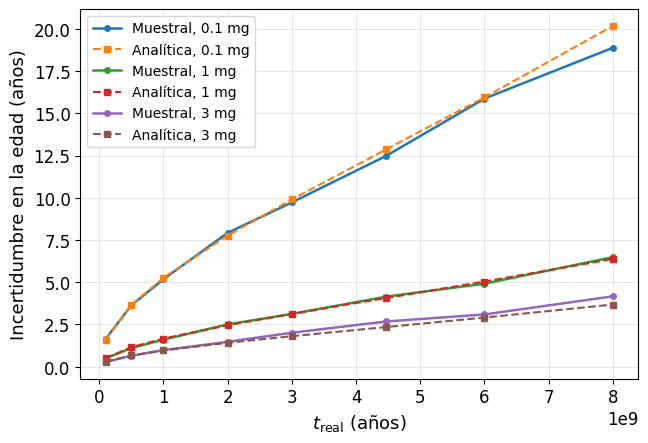

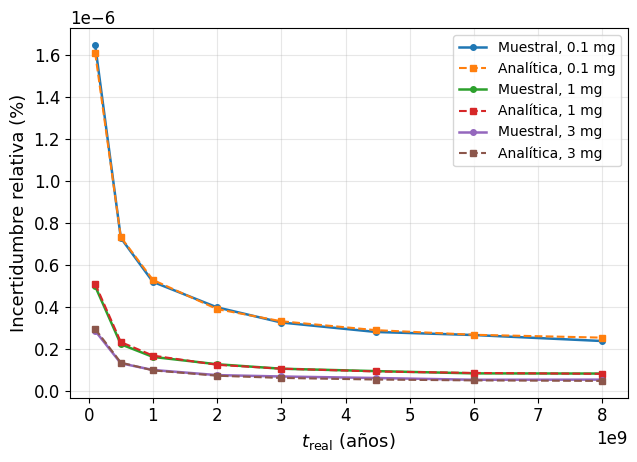

In [5]:
#########################################################
########## DEPENDENCIA CON LA MASA DE URANIO ############
#########################################################

# Tiempos reales para representar
tiempos_E3 = np.array([1.0e8, 5.0e8, 1.0e9, 2.0e9, 3.0e9, 4.47e9, 6.0e9, 8.0e9])

# Número de simulaciones independientes
M = 500

# Masas de uranio natural.
# Se mantienen por debajo de unos pocos mg para evitar problemas con el límite entero de np.random.binomial.
masas_U = np.array([1.0e-4, 1.0e-3, 3.0e-3])  # g: 0.1 mg, 1 mg y 3 mg

# Número inicial de núcleos de 238U para cada masa de uranio natural
N0_muestras = (masas_U / M_U * NA * abundancia_U238).astype(np.int64)

# Matrices para guardar resultados
media_t_est_E3 = np.zeros((len(N0_muestras), len(tiempos_E3)))
sigma_t_muestral_E3 = np.zeros((len(N0_muestras), len(tiempos_E3)))
sigma_t_analitica_E3 = np.zeros((len(N0_muestras), len(tiempos_E3)))

error_relativo_muestral_E3 = np.zeros((len(N0_muestras), len(tiempos_E3)))
error_relativo_analitico_E3 = np.zeros((len(N0_muestras), len(tiempos_E3)))

for i, N0_actual in enumerate(N0_muestras):

    for j, t_real in enumerate(tiempos_E3):

        # Probabilidad de supervivencia hasta t_real
        q = np.exp(-Lambda * t_real)

        # M simulaciones independientes del número final de núcleos supervivientes
        Np_final = np.random.binomial(int(N0_actual), q, size=M)

        # Evitar log(0), por si en algún caso la muestra queda agotada
        Np_final = Np_final[Np_final > 0]

        # Edad estimada para cada simulación
        t_est = -(1 / Lambda) * np.log(Np_final / N0_actual)

        # Edad media estimada
        media_t_est_E3[i, j] = np.mean(t_est)

        # Incertidumbre muestral
        sigma_t_muestral_E3[i, j] = np.std(t_est, ddof=1)

        # Incertidumbre analítica
        sigma_t_analitica_E3[i, j] = (1 / Lambda) * np.sqrt(
            (np.exp(Lambda * t_real) - 1) / N0_actual
        )

        # Incertidumbre relativa muestral
        error_relativo_muestral_E3[i, j] = sigma_t_muestral_E3[i, j] / media_t_est_E3[i, j]

        # Incertidumbre relativa analítica
        error_relativo_analitico_E3[i, j] = sigma_t_analitica_E3[i, j] / t_real


#########################################################
##### GRÁFICA INCERTIDUMBRE ABSOLUTA ####################
#########################################################

plt.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 10,
    "figure.figsize": (7.2, 4.8),
    "axes.grid": False,
    "lines.linewidth": 1.8
})

for i, masa in enumerate(masas_U):
    etiqueta = f'{1e3 * masa:g} mg'

    plt.plot(tiempos_E3, sigma_t_muestral_E3[i], 'o-', markersize=4, label=f'Muestral, {etiqueta}')
    plt.plot(tiempos_E3, sigma_t_analitica_E3[i], 's--', markersize=4, linewidth=1.5, label=f'Analítica, {etiqueta}')

plt.xlabel('$t_{\mathrm{real}}$ (años)')
plt.ylabel('Incertidumbre en la edad (años)')
plt.ticklabel_format(style='sci', axis='x', scilimits=(0, 0))

plt.legend()
plt.grid(True, alpha=0.3)

plt.savefig(os.path.join(carpeta_salida, 'U_E3_sigma_t_vs_treal.png'), dpi=300, bbox_inches='tight')
plt.show()


#########################################################
##### GRÁFICA INCERTIDUMBRE RELATIVA ####################
#########################################################

plt.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 10,
    "figure.figsize": (7.2, 4.8),
    "axes.grid": False,
    "lines.linewidth": 1.8
})

for i, masa in enumerate(masas_U):
    etiqueta = f'{1e3 * masa:g} mg'

    plt.plot(tiempos_E3, 100 * error_relativo_muestral_E3[i], 'o-', markersize=4, label=f'Muestral, {etiqueta}')
    plt.plot(tiempos_E3, 100 * error_relativo_analitico_E3[i], 's--', markersize=4, linewidth=1.5, label=f'Analítica, {etiqueta}')

plt.xlabel('$t_{\mathrm{real}}$ (años)')
plt.ylabel('Incertidumbre relativa (%)')
plt.ticklabel_format(style='sci', axis='both', scilimits=(0, 0))

plt.legend()
plt.grid(True, alpha=0.3)

plt.savefig(os.path.join(carpeta_salida, 'U_E3_sigma_relativa_vs_treal.png'), dpi=300, bbox_inches='tight')
plt.show()

In [6]:
#########################################################
##### EDAD APROXIMADA PARA ERROR RELATIVO >= UMBRAL #####
#########################################################

# Para el 238U, los tiempos umbral son muy grandes debido a su semivida y al elevado N0.
paso_umbral = 1.0e8

tiempos_umbral = np.arange(1.0e7, 8.0e11 + paso_umbral, paso_umbral)

umbrales = np.array([0.05, 0.10, 0.20])

tabla_umbral_E3 = []

for i, masa in enumerate(masas_U):

    N0_actual = N0_muestras[i]

    sigma_t_an = (1 / Lambda) * np.sqrt(
        (np.exp(Lambda * tiempos_umbral) - 1) / N0_actual
    )

    error_rel_an = sigma_t_an / tiempos_umbral

    tiempos_para_umbrales = []

    for umbral in umbrales:

        indices = np.where(error_rel_an >= umbral)[0]

        if len(indices) > 0:
            t_umbral = tiempos_umbral[indices[0]]
        else:
            t_umbral = np.nan

        tiempos_para_umbrales.append(t_umbral)

    tabla_umbral_E3.append([
        masa,
        N0_actual,
        tiempos_para_umbrales[0],
        tiempos_para_umbrales[1],
        tiempos_para_umbrales[2]
    ])


#########################################################
########## FUNCIONES DE FORMATO #########################
#########################################################

def formato_masa_mg(x):
    return f"{1e3 * x:g}"

def formato_entero(x):
    if np.isnan(x):
        return "--"
    return f"{x:.0f}"

def formato_cientifico_latex(x):
    if np.isnan(x):
        return "--"

    exponente = int(np.floor(np.log10(abs(x))))
    coeficiente = x / 10**exponente

    if np.isclose(coeficiente, round(coeficiente)):
        coeficiente_txt = f"{int(round(coeficiente))}"
    else:
        coeficiente_txt = f"{coeficiente:.2g}".replace(".", ",")

    return f"${coeficiente_txt}\\times 10^{{{exponente}}}$"

def formato_cientifico_notebook(x):
    if np.isnan(x):
        return "--"

    exponente = int(np.floor(np.log10(abs(x))))
    coeficiente = x / 10**exponente

    if np.isclose(coeficiente, round(coeficiente)):
        coeficiente_txt = f"{int(round(coeficiente))}"
    else:
        coeficiente_txt = f"{coeficiente:.2g}"

    return f"{coeficiente_txt}e{exponente}"


#########################################################
########## TABLA UMBRAL  5%, 10%, 20%  ##################
#########################################################

tabla_umbral_E3_notebook = pd.DataFrame({
    'masa de uranio (mg)': [formato_masa_mg(fila[0]) for fila in tabla_umbral_E3],
    'Núcleos iniciales de 238U': [formato_cientifico_notebook(fila[1]) for fila in tabla_umbral_E3],
    'edad para error >= 5% (años)': [formato_cientifico_notebook(fila[2]) for fila in tabla_umbral_E3],
    'edad para error >= 10% (años)': [formato_cientifico_notebook(fila[3]) for fila in tabla_umbral_E3],
    'edad para error >= 20% (años)': [formato_cientifico_notebook(fila[4]) for fila in tabla_umbral_E3]
})

display(tabla_umbral_E3_notebook)


#########################################################
########## TABLA LÁTEX DEL UMBRAL #######################
#########################################################

tabla_umbral_E3_latex = pd.DataFrame({
    r'$m_U$ (mg)': [formato_masa_mg(fila[0]) for fila in tabla_umbral_E3],
    r'$N_0(^{238}\mathrm{U})$': [formato_cientifico_latex(fila[1]) for fila in tabla_umbral_E3],
    r'$t_{5\%}$ (años)': [formato_cientifico_latex(fila[2]) for fila in tabla_umbral_E3],
    r'$t_{10\%}$ (años)': [formato_cientifico_latex(fila[3]) for fila in tabla_umbral_E3],
    r'$t_{20\%}$ (años)': [formato_cientifico_latex(fila[4]) for fila in tabla_umbral_E3]
})

codigo_latex_umbral_E3 = tabla_umbral_E3_latex.to_latex(
    index=False,
    escape=False
)

with open(os.path.join(carpeta_salida, 'U_tabla_E3_umbrales_error_relativo.tex'), 'w', encoding='utf-8') as f:
    f.write(codigo_latex_umbral_E3)


,masa de uranio (mg),Núcleos iniciales de 238U,edad para error >= 5% (años),edad para error >= 10% (años),edad para error >= 20% (años)
0,0.1,2.5e17,2.7e11,2.8e11,2.9e11
1,1,2.5e18,2.8e11,2.9e11,3e11
2,3,7.5e18,2.9e11,3e11,3.1e11
